# 🔍 Análise de Comentários de Restaurantes

**Objetivo:** transformar avaliações de delivery (nota + texto livre) em respostas para perguntas de negócio:

1. Os dados estão confiáveis? O que precisou ser corrigido?
2. O que mais derruba a nota de um pedido?
3. Sobre o que os clientes reclamam — e isso muda por restaurante?
4. Onde agir primeiro?

> ⚠️ **Base sintética.** Os dados foram gerados por `src/gerar_dados.py` imitando o formato e os problemas de uma base real
> de avaliações de delivery. Nenhum dado é de clientes ou restaurantes reais. A metodologia é a mesma que seria aplicada a dados reais.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path("..") / "src"))

import pandas as pd
from IPython.display import Image, display

import limpeza, analise
pd.set_option("display.max_colwidth", 80)

## 1. Conhecendo a base bruta

In [2]:
bruto = pd.read_csv("../data/raw/avaliacoes_raw.csv", dtype=str)
print(bruto.shape)
bruto.head(8)

(6180, 9)


,id_avaliacao,data_pedido,restaurante,categoria,cidade,nota,tempo_entrega_min,valor_pedido,comentario
0,103691,2026-01-03 19:54,Casa Fogo Express,brasileira,Belo Horizonte,3,59.0,26.92,Feijoada chegou fria e murcha mas ótimo custo-benefício
1,100969,2026-02-13 21:01,Casa Brasa da Vila,lanches,São Paulo,3,43.0,15.0,Porção minúscula 😐
2,102450,2026-05-21 21:32,Casa Folha da Vila,Hamburguer,Curitiba,4,50.0,53.46,Entregador muito educado
3,103082,21/04/2026 20:16,Recanto Arte da Vila,Sobremesas,São Paulo,5,30.0,"R$ 27,67",Preço justo pela quantidade mas embalagem caprichada
4,103727,15/05/26,Cantina Grão Prime,Comida Brasileira,Rio de Janeiro,3,42.0,27.44,Veio tudo revirado. melhor feijoada que já pedi
5,102366,22/06/2026 19:14,Ateliê Grão da Esquina,Pizza,Pelotas,2,55.0,"R$ 68,21",NaN
6,101954,2026-02-05 13:49,Point Arte Gourmet,Hambúrguer,São Paulo,4,41.0,48.41,Comida muito saborosa 👍
7,105391,2026-07-06 22:12,Point Sabor Express,pizza,São Paulo,4,0.0,38.03,"Veio tudo bem embalado, sem vazar"


Logo nas primeiras linhas aparecem problemas: datas em formatos diferentes, `R$ 27,67` como texto, categorias escritas de vários jeitos, tempo de entrega `0`.

In [3]:
print("Grafias de categoria:", bruto["categoria"].nunique())
print(bruto["categoria"].value_counts().head(12).to_string())

Grafias de categoria: 24
categoria
pizza                496
Pizza                489
Pizzaria             476
PIZZA                430
burger               423
hamburguer           414
Hambúrguer           403
Hamburguer           390
brasileira           329
Brasileira           320
Comida Brasileira    306
Japonesa             195


In [4]:
print("Valores de nota encontrados:", sorted(bruto["nota"].dropna().unique(), key=float))
print("Nulos por coluna:")
bruto.isna().sum()

Valores de nota encontrados: ['0', '1', '1.0', '2', '2.0', '3', '3.0', '4', '4.0', '5', '5.0', '6', '10']
Nulos por coluna:


id_avaliacao           0
data_pedido            0
restaurante            0
categoria              0
cidade                61
nota                   0
tempo_entrega_min    123
valor_pedido          52
comentario           399
dtype: int64

## 2. Limpeza

Toda a limpeza está em `src/limpeza.py`, uma função testável que devolve a base limpa **e** um log do que foi feito.
Decisões principais:

| Problema | Decisão | Por quê |
|---|---|---|
| Avaliações duplicadas | remover | contariam duas vezes a mesma opinião |
| 24 grafias de categoria | mapear para 7 | `sushi`, `japonesa` e `Comida Japonesa` são a mesma coisa |
| Nota 0, 6 ou 10 | virar nulo | fora da escala 1–5; não dá para saber a nota real |
| Tempo ≤ 0 ou 999 min | virar nulo | erro de sistema, não entrega real |
| Comentário `"ok"`, `"-"`, `"."` | virar nulo | não carrega opinião analisável |
| Datas `dd/mm/aa` sem hora | manter data, hora nula | o dia ainda serve para análise semanal |

Valores inválidos viram **nulo** em vez de apagar a linha inteira: uma avaliação com tempo de entrega errado ainda tem nota e comentário úteis.

In [5]:
df, log = limpeza.limpar(bruto)
log

,etapa,linhas_afetadas,detalhe
0,Base original,6180,9 colunas
1,Duplicatas exatas removidas,180,mesma avaliação enviada 2x
2,IDs repetidos removidos,0,mantida a primeira ocorrência
3,Categoria padronizada,4317,24 grafias -> 7 categorias
4,Cidade padronizado(a),494,12 valores distintos -> 6
5,Restaurante padronizado(a),300,114 valores distintos -> 57
6,Datas convertidas,6000,3 formatos; 618 sem horário (dd/mm/aa)
7,Notas fora da escala 1–5 anuladas,25,"ex.: 0, 6, 10"
8,Valores com 'R$' e vírgula convertidos,892,texto -> número
9,Tempos de entrega implausíveis anulados,38,"fora de 5–180 min (ex.: -5, 0, 999)"


In [6]:
df[["data_pedido", "restaurante", "categoria", "cidade", "nota",
    "tempo_entrega_min", "valor_pedido", "comentario"]].head()

,data_pedido,restaurante,categoria,cidade,nota,tempo_entrega_min,valor_pedido,comentario
0,2026-01-03 19:54:00,Casa Fogo Express,Brasileira,Belo Horizonte,3,59.0,26.92,Feijoada chegou fria e murcha mas ótimo custo-benefício
1,2026-02-13 21:01:00,Casa Brasa da Vila,Lanches,São Paulo,3,43.0,15.0,Porção minúscula 😐
2,2026-05-21 21:32:00,Casa Folha da Vila,Hambúrguer,Curitiba,4,50.0,53.46,Entregador muito educado
3,2026-04-21 20:16:00,Recanto Arte da Vila,Doces & Sobremesas,São Paulo,5,30.0,27.67,Preço justo pela quantidade mas embalagem caprichada
4,2026-05-15 00:00:00,Cantina Grão Prime,Brasileira,Rio de Janeiro,3,42.0,27.44,Veio tudo revirado. melhor feijoada que já pedi


## 3. Temas dos comentários

Cada comentário é normalizado (minúsculas, sem acento, sem emoji) e marcado com temas por **regras de palavras-chave**.
É uma linha de base transparente: dá para ler a regra e entender cada classificação.

Um cuidado importante foram os **falsos positivos**: "veio tudo bem embalado, *sem vazar*" e "*preço justo*" são elogios,
mas regras ingênuas (`vaz`, `preco`) os contariam como reclamação. As regras finais foram conferidas contra todas as frases da base.

In [7]:
df = analise.marcar_temas(df)
for t, regra in analise.TEMAS.items():
    print(f"{t:<18} {regra}")

Atraso             demor|atras|eternidade
Comida fria        \bfri[oa]\b|gelad|murch
Pedido errado      errad|faltou|esquec|veio com cebola
Embalagem          rasgad|vazou|revirad
Preço              \bcar[oa]\b|preco salgado|taxa de entrega absurda
Quantidade         minuscul|pouca comida
Sabor (crítica)    sem sabor|\bcru[a]?\b|muito salgado|requentad
Sabor (elogio)     saboros|sabor incrivel|delicia|tempero perfeito|melhor
Entrega (elogio)   rapido|antes do previsto|educad|quentinho


In [8]:
exemplos = df[df["nota"] <= 2].dropna(subset=["comentario"]).sample(6, random_state=3)
cols = ["nota", "comentario"] + [f"tema_{t}" for t in analise.TEMAS_NEGATIVOS]
exemplos[cols].rename(columns=lambda c: c.replace("tema_", ""))

,nota,comentario,Atraso,Comida fria,Pedido errado,Embalagem,Preço,Quantidade,Sabor (crítica)
1095,2,"Chegou frio, sem sabor nenhum 😡",False,True,False,False,False,False,True
5203,2,Esperei uma eternidade,True,False,False,False,False,False,False
4286,1,Esperei uma eternidade 🙄,True,False,False,False,False,False,False
3276,2,Chegou frio!! faltou o refrigerante 👎,False,True,True,False,False,False,False
815,2,Esperei uma eternidade mas esqueceram a sobremesa,True,False,True,False,False,False,False
3690,2,Preço salgado,False,False,False,False,True,False,False


## 4. Análise exploratória

### 4.1 Como as notas se distribuem

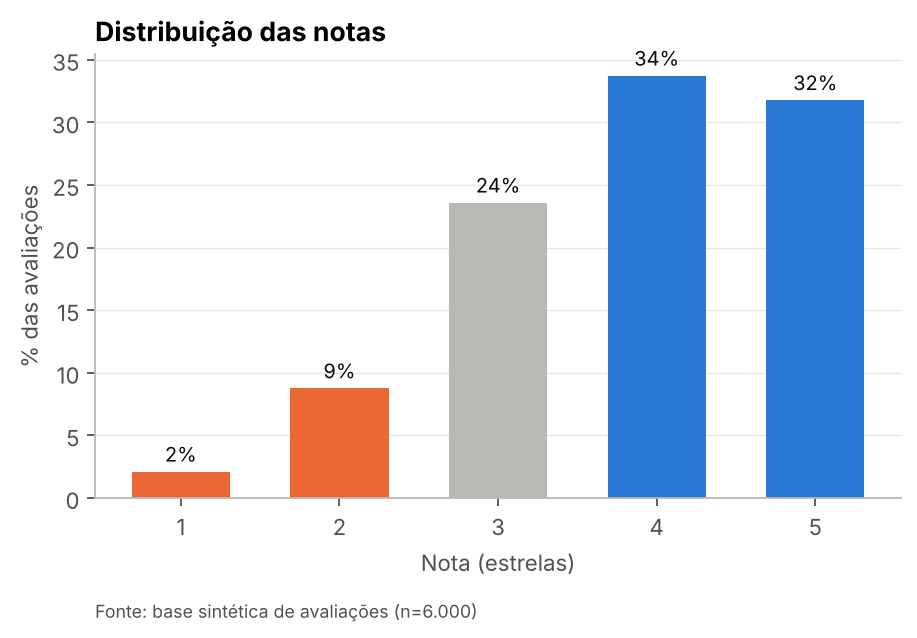

Nota média: 3.84  |  negativas (1–2★): 10.9%  |  com comentário escrito: 92.3%


In [9]:
analise.fig_distribuicao_notas(df)
display(Image("../figures/01_distribuicao_notas.png"))
com_nota = df.dropna(subset=["nota"])
print(f"Nota média: {com_nota['nota'].mean():.2f}  |  "
      f"negativas (1–2★): {(com_nota['nota'] <= 2).mean():.1%}  |  "
      f"com comentário escrito: {df['tem_comentario'].mean():.1%}")

A maioria das avaliações é positiva (4–5★), como é típico em plataformas de avaliação. Por isso a **média sozinha esconde problemas**:
o que interessa é *onde* se concentram os ~11% de avaliações negativas.

### 4.2 O tempo de entrega e a nota

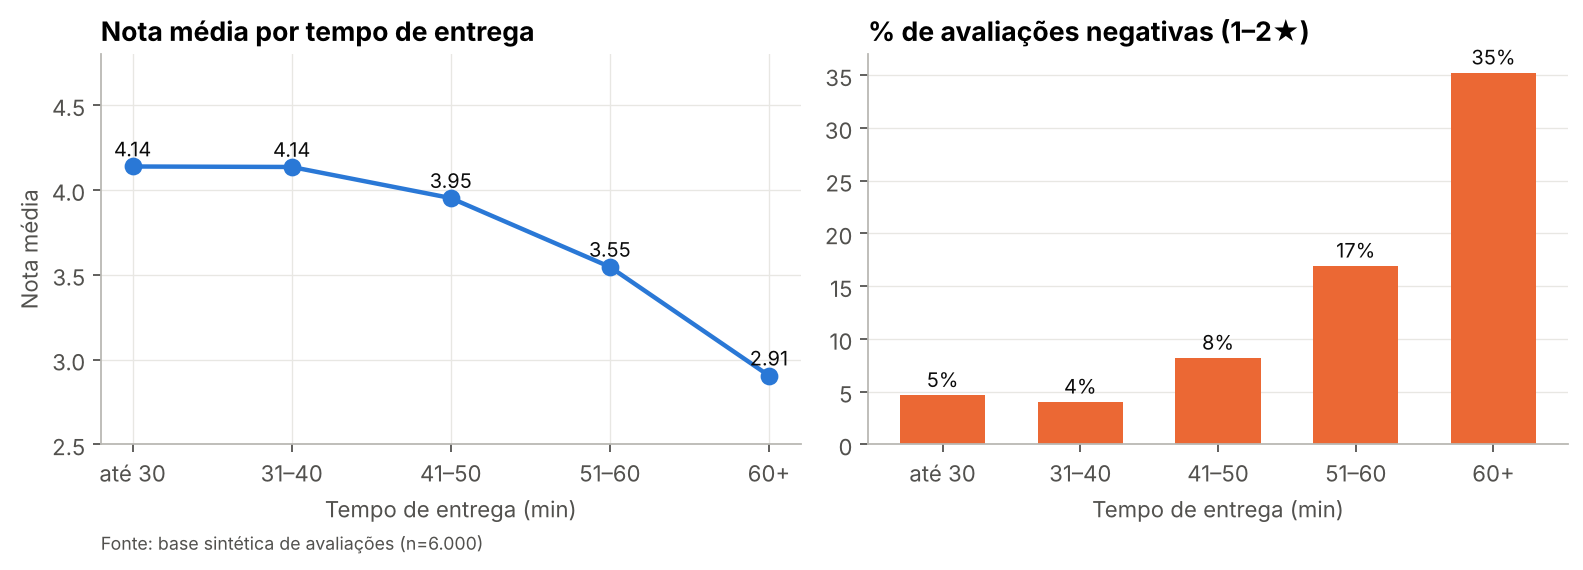

,nota_media,pct_neg,n
faixa_entrega,,,
até 30,4.14,4.65,796
31–40,4.14,4.02,1492
41–50,3.95,8.19,1795
51–60,3.55,16.92,1206
60+,2.91,35.23,528


In [10]:
tempo = analise.fig_tempo_vs_nota(df)
display(Image("../figures/02_tempo_entrega_vs_nota.png"))
tempo.round(2)

**Este é o achado principal.** Até 40 minutos a nota é estável (~4,1). A partir daí ela cai rápido,
e a **taxa de avaliações negativas sai de ~5% para 35%** nas entregas acima de 60 minutos.
Não é uma queda linear: existe um *limite de tolerância* do cliente por volta de 40–50 minutos.

In [11]:
print("Correlação tempo × nota:", round(com_nota[["tempo_entrega_min", "nota"]].astype(float).corr().iloc[0, 1], 2))

Correlação tempo × nota: -0.33


### 4.3 Quando os atrasos acontecem

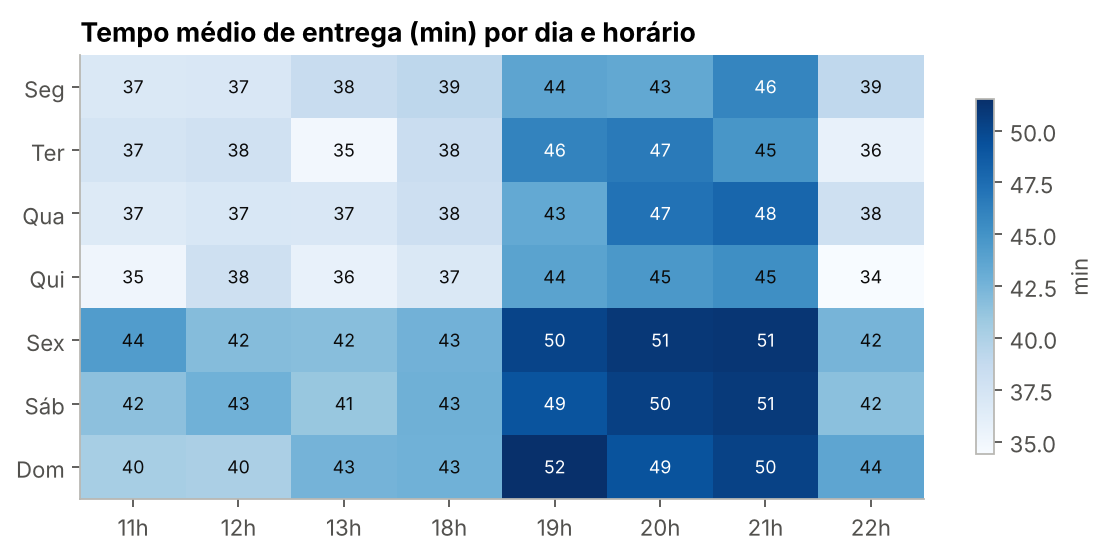

Tempo médio 19h–21h: 47.9 min  |  demais horários: 39.8 min
Sex–Dom: 46.2 min  |  Seg–Qui: 41.2 min


In [12]:
analise.fig_heatmap_pico(df)
display(Image("../figures/05_heatmap_pico.png"))
noite = df["hora"].between(19, 21)
print(f"Tempo médio 19h–21h: {df.loc[noite, 'tempo_entrega_min'].mean():.1f} min  |  "
      f"demais horários: {df.loc[df['hora'].notna() & ~noite, 'tempo_entrega_min'].mean():.1f} min")
print(f"Sex–Dom: {df.loc[df['fim_de_semana'], 'tempo_entrega_min'].mean():.1f} min  |  "
      f"Seg–Qui: {df.loc[~df['fim_de_semana'], 'tempo_entrega_min'].mean():.1f} min")

O pico de jantar (19h–21h) somado ao fim de semana (sex–dom) é onde o tempo médio passa de **50 minutos** — exatamente
a faixa em que as avaliações negativas disparam. É ali que reforço de entregadores ou ajuste do tempo prometido teria mais efeito.

*Observação:* ~10% das datas vieram no formato `dd/mm/aa`, sem horário; essas linhas ficam de fora deste gráfico.

### 4.4 Categorias

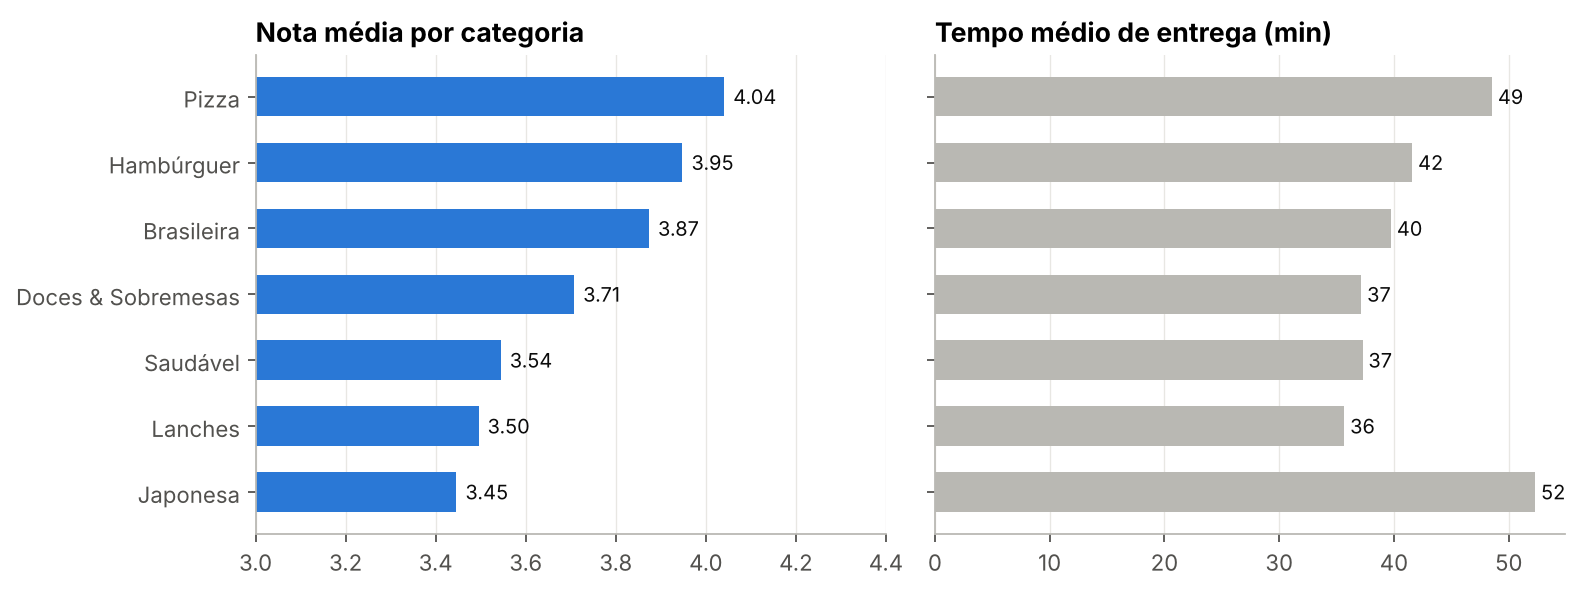

,nota_media,tempo_medio,n
categoria,,,
Japonesa,3.45,52.31,713
Lanches,3.5,35.68,528
Saudável,3.54,37.27,202
Doces & Sobremesas,3.71,37.16,213
Brasileira,3.87,39.75,933
Hambúrguer,3.95,41.60,1571
Pizza,4.04,48.56,1840


In [13]:
cats = analise.fig_categorias(df)
display(Image("../figures/03_categorias.png"))
cats.round(2)

**Japonesa** tem a pior nota média e o maior tempo de entrega. Mas tempo não explica tudo: **Pizza** também é lenta (~49 min)
e tem a melhor nota. Ou seja, a categoria sozinha não é a causa — vale olhar restaurante a restaurante (seção 4.6).

### 4.5 Sobre o que os clientes reclamam

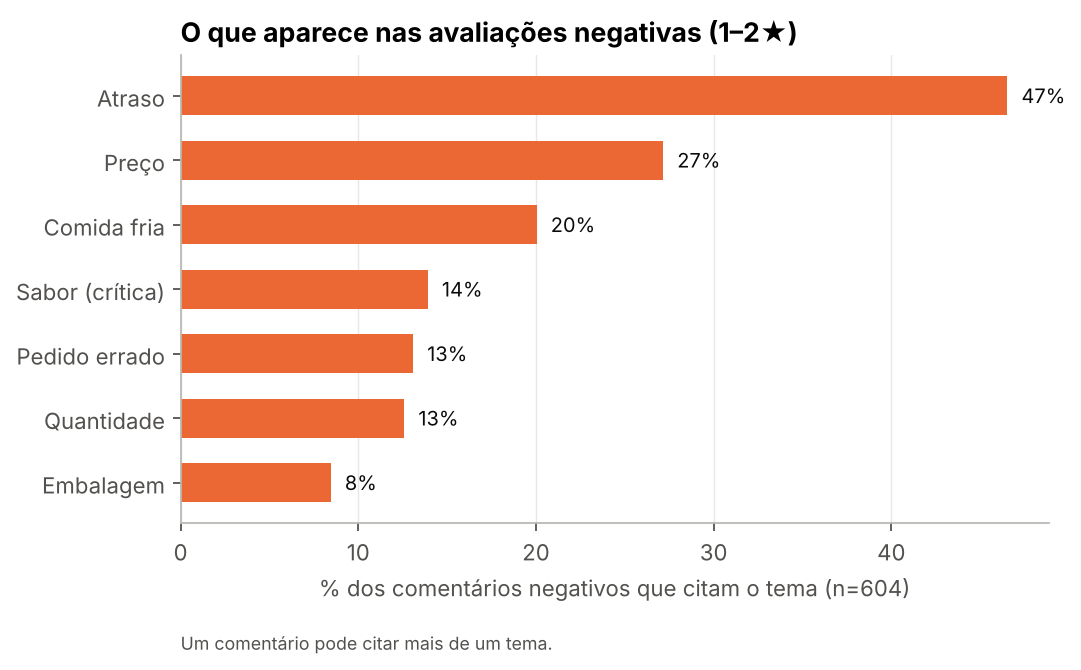

Atraso             46.5
Preço              27.2
Comida fria        20.0
Sabor (crítica)    13.9
Pedido errado      13.1
Quantidade         12.6
Embalagem           8.4
dtype: float64

In [14]:
temas = analise.fig_temas_negativos(df)
display(Image("../figures/04_temas_negativos.png"))
temas.round(1)

**Atraso** aparece em quase metade das avaliações negativas, seguido de **preço** e **comida fria** (que, na prática, também é
consequência de demora). Problemas de operação da cozinha (pedido errado, quantidade, embalagem) aparecem menos, mas são
concentrados em poucos restaurantes, como mostra a próxima seção.

In [15]:
nota4 = df[df["nota"] == 4]
ressalva = nota4[[f"tema_{t}" for t in analise.TEMAS_NEGATIVOS]].any(axis=1)
print(f"{ressalva.mean():.0%} das avaliações 4★ trazem alguma crítica no texto.")
nota4.loc[ressalva, "comentario"].head(5).to_list()

31% das avaliações 4★ trazem alguma crítica no texto.


['Chegou quentinho!! embalagem caprichada mas demorou demais',
 'Embalagem caprichada... preço justo pela quantidade... porção minúscula',
 'Ótimo custo-benefício mas veio pouca comida',
 'Estava uma delícia, preço salgado',
 'Melhor lanche que já pedi!! preço justo pela quantidade... comida gelada 😍']

Um detalhe que só aparece lendo o texto: **cerca de 1 em cada 3 avaliações de 4 estrelas traz uma reclamação** ("chegou quentinho... taxa de entrega absurda").
Olhando só a nota, esses sinais de alerta passam despercebidos.

### 4.6 Restaurantes: onde agir primeiro

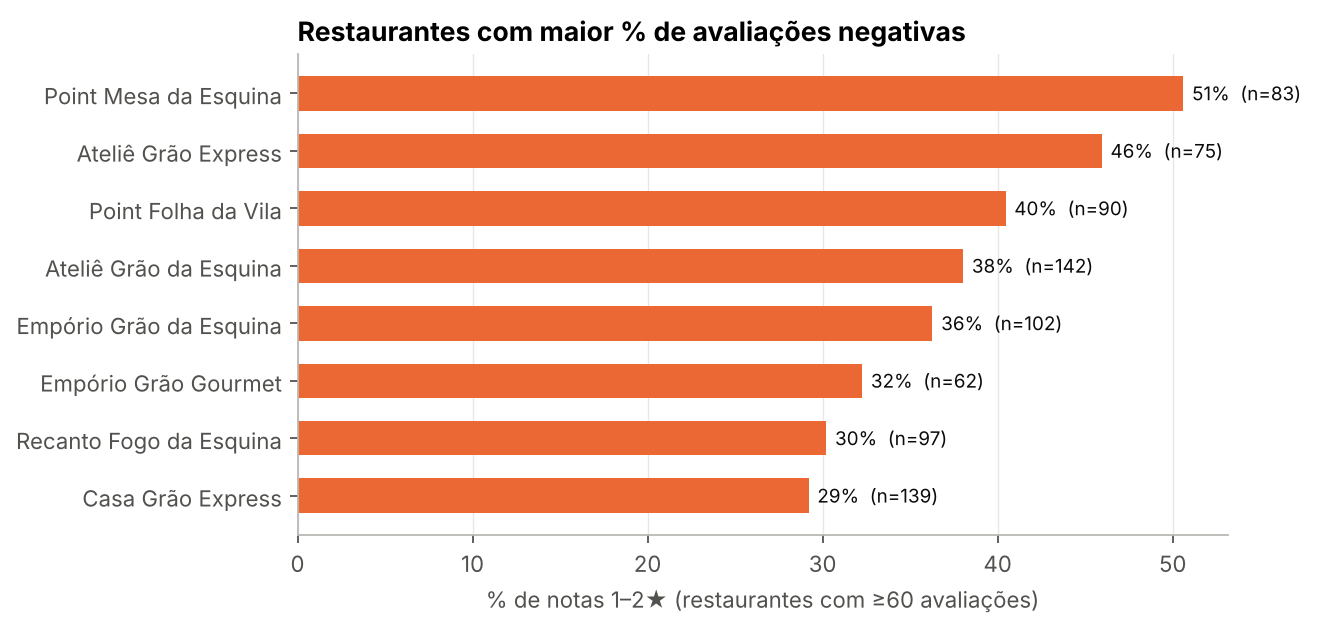

,n,nota,pct_neg,atraso
restaurante,,,,
Point Mesa da Esquina,83,2.5,50.6,0.1
Ateliê Grão Express,75,2.6,45.9,0.1
Point Folha da Vila,90,2.9,40.4,0.2
Ateliê Grão da Esquina,142,2.7,38.0,0.4
Empório Grão da Esquina,102,2.8,36.3,0.1
Empório Grão Gourmet,62,2.9,32.3,0.1
Recanto Fogo da Esquina,97,2.9,30.2,0.4
Casa Grão Express,139,3.0,29.2,0.4


In [16]:
rank = analise.fig_ranking_restaurantes(df)
display(Image("../figures/06_ranking_restaurantes.png"))
rank.head(8).round(1)

In [17]:
dores = analise.dores_por_restaurante(df, rank.head(5).index)
dores.style.background_gradient(cmap="Oranges", axis=1).format("{:.0f}%")

,Atraso,Comida fria,Pedido errado,Embalagem,Preço,Quantidade,Sabor (crítica)
restaurante,,,,,,,
Ateliê Grão Express,13%,7%,49%,0%,48%,0%,0%
Ateliê Grão da Esquina,47%,3%,0%,0%,50%,0%,0%
Empório Grão da Esquina,14%,4%,51%,0%,46%,0%,0%
Point Folha da Vila,22%,8%,0%,0%,43%,0%,51%
Point Mesa da Esquina,10%,7%,47%,0%,41%,0%,0%


**Preço** aparece alto em todos os cinco (43–53% das críticas) — é uma queixa de fundo, que não diferencia ninguém.
O que muda de um para outro é a **segunda dor**, e é ela que define a ação:

- **Point Mesa da Esquina**, **Ateliê Grão Express** e **Empório Grão da Esquina**: ~50% das críticas são de **pedido errado** → conferência na cozinha, não logística.
- **Point Folha da Vila**: 65% citam **sabor** → produto/receita.
- **Ateliê Grão da Esquina**: o problema é **atraso** (47%) → capacidade ou tempo de preparo.

Um alerta genérico de "nota baixa" mandaria o mesmo recado para todos; a leitura dos comentários permite uma recomendação específica.

## 5. Conclusões

| # | Insight | Ação sugerida |
|---|---|---|
| 1 | Nota estável até 40 min; negativas vão de ~5% para **35%** acima de 60 min | Monitorar a % de pedidos acima de 50 min como indicador de risco |
| 2 | Pico **sex–dom, 19h–21h** passa de 50 min em média | Reforço de entregadores / tempo prometido mais realista nesses horários |
| 3 | **Atraso** está em ~47% das críticas; comida fria em 20% | Priorizar logística antes de cardápio |
| 4 | ~1/3 das avaliações 4★ têm crítica escondida no texto | Analisar texto, não só a nota |
| 5 | Além do preço (comum a todos), os piores restaurantes têm dores **diferentes**: pedido errado × sabor × atraso | Feedback personalizado ao parceiro, gerado a partir dos temas |

## 6. Limitações e próximos passos

- **Dados sintéticos**: os padrões foram embutidos de propósito para exercitar o método; em dados reais os efeitos seriam mais ruidosos.
- **Regras de palavras-chave** não capturam ironia, gírias e erros de digitação. O script `src/temas_llm.py` classifica uma
  amostra com um LLM e mede a concordância com as regras — o caminho natural para escalar a análise com GenAI.
- **Correlação ≠ causalidade**: restaurantes lentos podem ser piores em outras coisas também. Um teste A/B no tempo prometido mediria o efeito real.
- Próximo passo de produto: gerar automaticamente um resumo semanal por restaurante ("seus clientes reclamaram de X; sugestão: Y").